In [6]:
!pip -q install folium

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

np.random.seed(42)

print("Semua library berhasil disiapkan.")

Semua library berhasil disiapkan.


In [7]:
jumlah_per_kategori = 80

kategori = {
    "Pertanian": {
        "vegetasi": (70, 95),
        "jalan": (20, 55),
        "panas": (10, 40),
        "pusat": (-1.5, 114.0)
    },
    "Pembangunan Jalan": {
        "vegetasi": (55, 85),
        "jalan": (75, 100),
        "panas": (10, 35),
        "pusat": (0.5, 116.0)
    },
    "Pertambangan": {
        "vegetasi": (50, 80),
        "jalan": (40, 75),
        "panas": (25, 60),
        "pusat": (-1.0, 117.0)
    },
    "Kebakaran": {
        "vegetasi": (80, 100),
        "jalan": (10, 45),
        "panas": (75, 100),
        "pusat": (-2.0, 111.5)
    }
}

baris = []

for nama, info in kategori.items():
    for i in range(jumlah_per_kategori):
        lat0, lon0 = info["pusat"]

        baris.append({
            "perubahan_vegetasi": np.random.uniform(*info["vegetasi"]),
            "aktivitas_jalan": np.random.uniform(*info["jalan"]),
            "indikator_panas": np.random.uniform(*info["panas"]),
            "latitude": lat0 + np.random.normal(0, 0.35),
            "longitude": lon0 + np.random.normal(0, 0.35),
            "penyebab": nama
        })

df = pd.DataFrame(baris)

print("Jumlah data:", len(df))
print("\nDistribusi kategori:")
print(df["penyebab"].value_counts())

display(df.head())

Jumlah data: 320

Distribusi kategori:
penyebab
Pertanian            80
Pembangunan Jalan    80
Pertambangan         80
Kebakaran            80
Name: count, dtype: int64


,perubahan_vegetasi,aktivitas_jalan,indikator_panas,latitude,longitude,penyebab
0,79.363503,53.275001,31.959818,-1.889158,114.111616,Pertanian
1,73.899863,22.032926,35.985284,-0.947276,114.268602,Pertanian
2,70.514612,53.946845,34.973279,-1.703307,113.816191,Pertanian
3,74.585113,30.648479,25.742693,-2.103721,113.803199,Pertanian
4,85.296322,24.882285,18.764339,-1.746170,113.251133,Pertanian


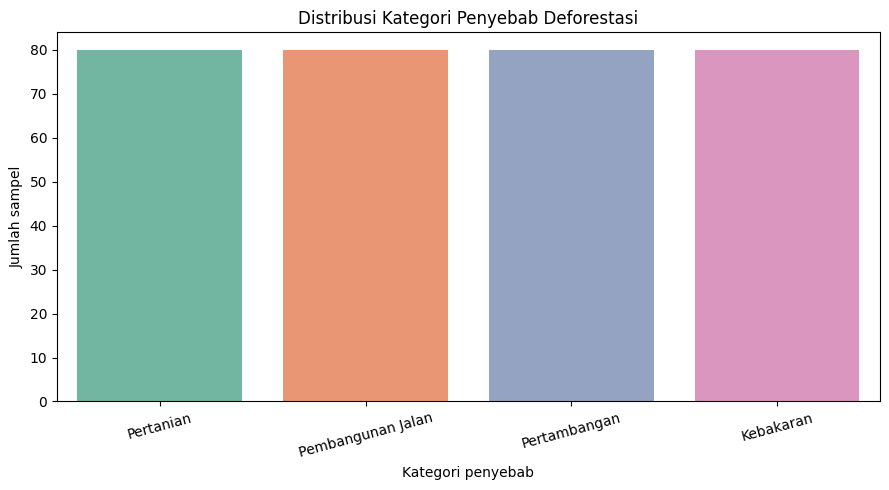

In [8]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="penyebab",
    hue="penyebab",
    order=df["penyebab"].value_counts().index,
    palette="Set2",
    legend=False
)

plt.title("Distribusi Kategori Penyebab Deforestasi")
plt.xlabel("Kategori penyebab")
plt.ylabel("Jumlah sampel")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [9]:
fitur = [
    "perubahan_vegetasi",
    "aktivitas_jalan",
    "indikator_panas"
]

X = df[fitur]
y = df["penyebab"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Model selesai dilatih.")

Jumlah data training: 240
Jumlah data testing: 80
Model selesai dilatih.


In [10]:
akurasi = accuracy_score(y_test, y_pred)

print(f"Akurasi model: {akurasi:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi model: 96.25%

Classification Report:
                   precision    recall  f1-score   support

        Kebakaran       1.00      1.00      1.00        20
Pembangunan Jalan       1.00      1.00      1.00        20
     Pertambangan       1.00      0.85      0.92        20
        Pertanian       0.87      1.00      0.93        20

         accuracy                           0.96        80
        macro avg       0.97      0.96      0.96        80
     weighted avg       0.97      0.96      0.96        80



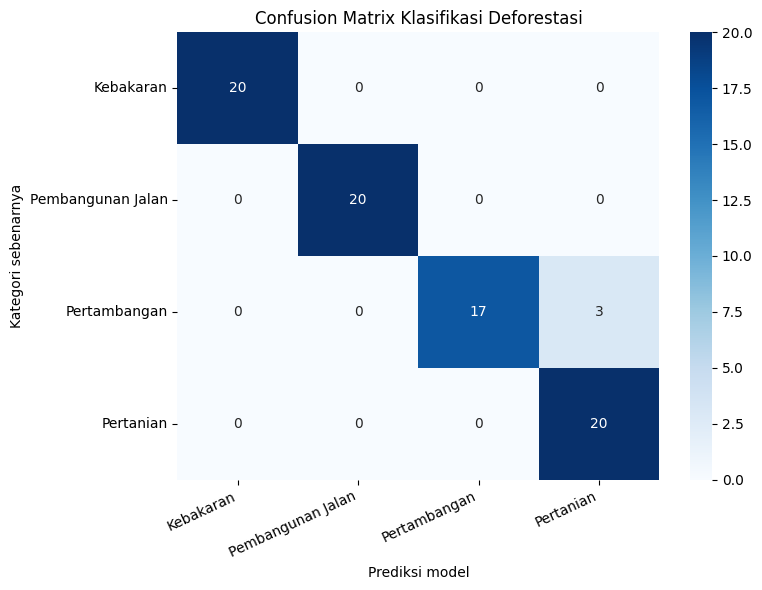

In [11]:
labels = model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix Klasifikasi Deforestasi")
plt.xlabel("Prediksi model")
plt.ylabel("Kategori sebenarnya")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

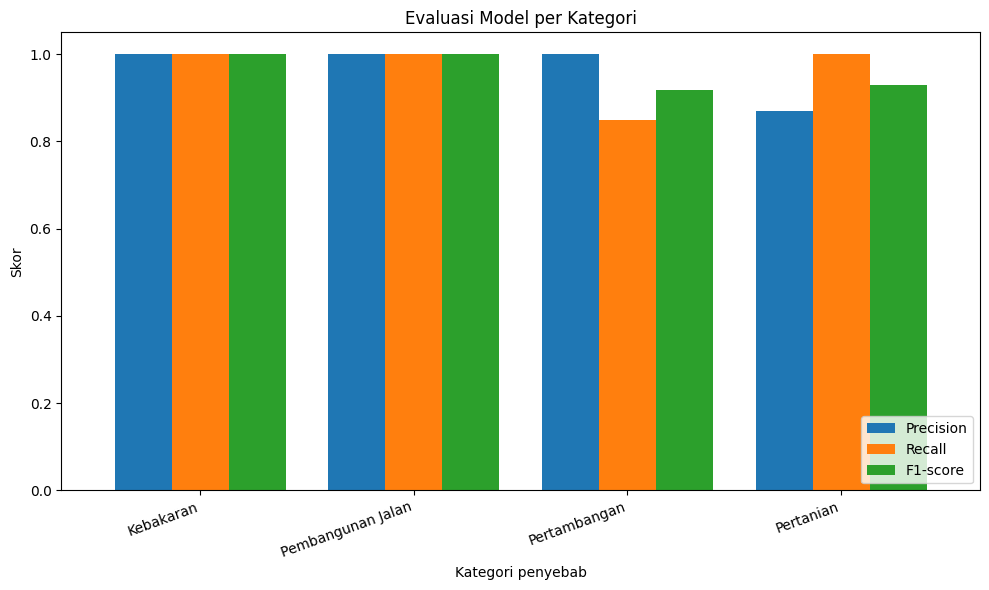

,Kategori,Precision,Recall,F1-score
0,Kebakaran,1.00,1.00,1.000
1,Pembangunan Jalan,1.00,1.00,1.000
2,Pertambangan,1.00,0.85,0.919
3,Pertanian,0.87,1.00,0.930


In [12]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=labels,
    zero_division=0
)

hasil_metrik = pd.DataFrame({
    "Kategori": labels,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
})

hasil_plot = hasil_metrik.set_index("Kategori")

hasil_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Evaluasi Model per Kategori")
plt.xlabel("Kategori penyebab")
plt.ylabel("Skor")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(hasil_metrik.round(3))

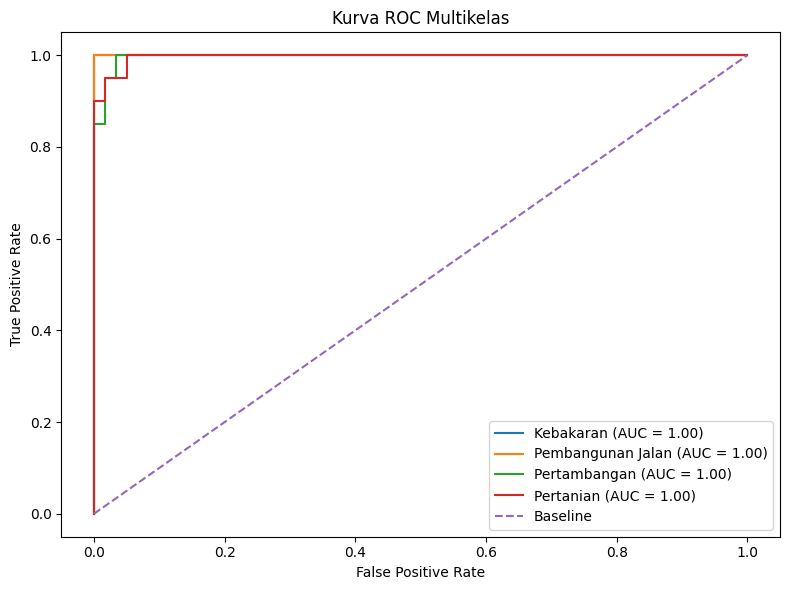

In [13]:
y_test_bin = label_binarize(y_test, classes=labels)

plt.figure(figsize=(8, 6))

for i, nama in enumerate(labels):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    nilai_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{nama} (AUC = {nilai_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline")
plt.title("Kurva ROC Multikelas")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

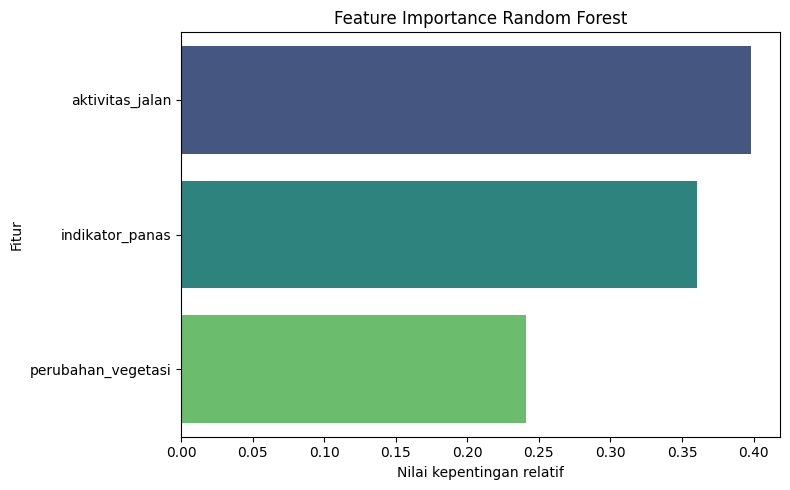

,Fitur,Importance
1,aktivitas_jalan,0.399
2,indikator_panas,0.361
0,perubahan_vegetasi,0.241


In [14]:
kepentingan = pd.DataFrame({
    "Fitur": fitur,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=kepentingan,
    x="Importance",
    y="Fitur",
    hue="Fitur",
    palette="viridis",
    legend=False
)

plt.title("Feature Importance Random Forest")
plt.xlabel("Nilai kepentingan relatif")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

display(kepentingan.round(3))

In [15]:
kasus_baru = pd.DataFrame([{
    "perubahan_vegetasi": 92,
    "aktivitas_jalan": 25,
    "indikator_panas": 90
}])

prediksi = model.predict(kasus_baru)[0]
probabilitas = model.predict_proba(kasus_baru)[0]

print("Prediksi penyebab:", prediksi)
print("\nProbabilitas per kategori:")

for nama, nilai in zip(model.classes_, probabilitas):
    print(f"{nama}: {nilai:.2%}")

Prediksi penyebab: Kebakaran

Probabilitas per kategori:
Kebakaran: 98.00%
Pembangunan Jalan: 0.00%
Pertambangan: 0.00%
Pertanian: 2.00%


In [19]:

import folium
from folium.plugins import Fullscreen

warna = {
    "Pertanian": "green",
    "Pembangunan Jalan": "blue",
    "Pertambangan": "orange",
    "Kebakaran": "red"
}

# Basemap Esri sebagai pengganti CartoDB
peta = folium.Map(
    location=[-1.5, 114.5],
    zoom_start=5,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(peta)

# Tampilkan titik simulasi
sampel_peta = df.sample(
    n=min(160, len(df)),
    random_state=42
)

for _, row in sampel_peta.iterrows():
    nama = row["penyebab"]

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=5,
        color=warna[nama],
        fill=True,
        fill_color=warna[nama],
        fill_opacity=0.8,
        tooltip=nama,
        popup=f"Kategori simulasi: {nama}"
    ).add_to(peta)

# Legenda
legenda = """
<div style="
position: fixed; bottom: 25px; left: 25px;
width: 205px; background: white;
border: 1px solid gray; border-radius: 6px;
padding: 10px; z-index: 9999; font-size: 13px;">
<b>Legenda — Data Simulasi</b><br>
<span style="color:green">●</span> Pertanian<br>
<span style="color:blue">●</span> Pembangunan Jalan<br>
<span style="color:orange">●</span> Pertambangan<br>
<span style="color:red">●</span> Kebakaran<br>
<hr>
<small>Lokasi bukan data aktual.</small>
</div>
"""

peta.get_root().html.add_child(
    folium.Element(legenda)
)

Fullscreen(position="topright").add_to(peta)

display(peta)
